# ΕΡΓΑΣΙΑ 2 - KNN

### ΕΙΣΑΓΩΓΗ ΒΙΒΛΙΟΘΗΚΩΝ

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

## ΜΕΡΟΣ 1 - KNN

### ΕΡΩΤΗΜΑ 1

In [13]:
df = pd.read_csv('airline_passenger_satisfaction.csv')
df

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,129876,Male,28,Returning,Personal,Economy Plus,447,2,3.0,4,...,5,1,4,4,4,5,4,4,4,Neutral or Dissatisfied
129876,129877,Male,41,Returning,Personal,Economy Plus,308,0,0.0,5,...,5,2,5,2,2,4,3,2,5,Neutral or Dissatisfied
129877,129878,Male,42,Returning,Personal,Economy Plus,337,6,14.0,5,...,3,3,4,3,3,4,2,3,5,Neutral or Dissatisfied
129878,129879,Male,50,Returning,Personal,Economy Plus,337,31,22.0,4,...,4,4,5,3,3,4,5,3,5,Satisfied


In [14]:
#Create a dataframe with numeric features
numericDf = df.select_dtypes(include=[np.number]).drop(columns=["ID"])
numericDf

,Age,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling
0,48,821,2,5.0,3,3,4,3,3,3,5,2,5,5,5,3,5,5
1,35,821,26,39.0,2,2,3,5,2,5,4,5,5,3,5,2,5,5
2,41,853,0,0.0,4,4,4,5,4,3,5,3,5,5,3,4,3,3
3,50,1905,0,0.0,2,2,3,4,2,5,5,5,4,4,5,2,5,5
4,49,3470,0,1.0,3,3,3,5,3,3,4,4,5,4,3,3,3,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,28,447,2,3.0,4,4,4,4,2,5,1,4,4,4,5,4,4,4
129876,41,308,0,0.0,5,3,5,3,4,5,2,5,2,2,4,3,2,5
129877,42,337,6,14.0,5,2,4,2,1,3,3,4,3,3,4,2,3,5
129878,50,337,31,22.0,4,4,3,4,1,4,4,5,3,3,4,5,3,5


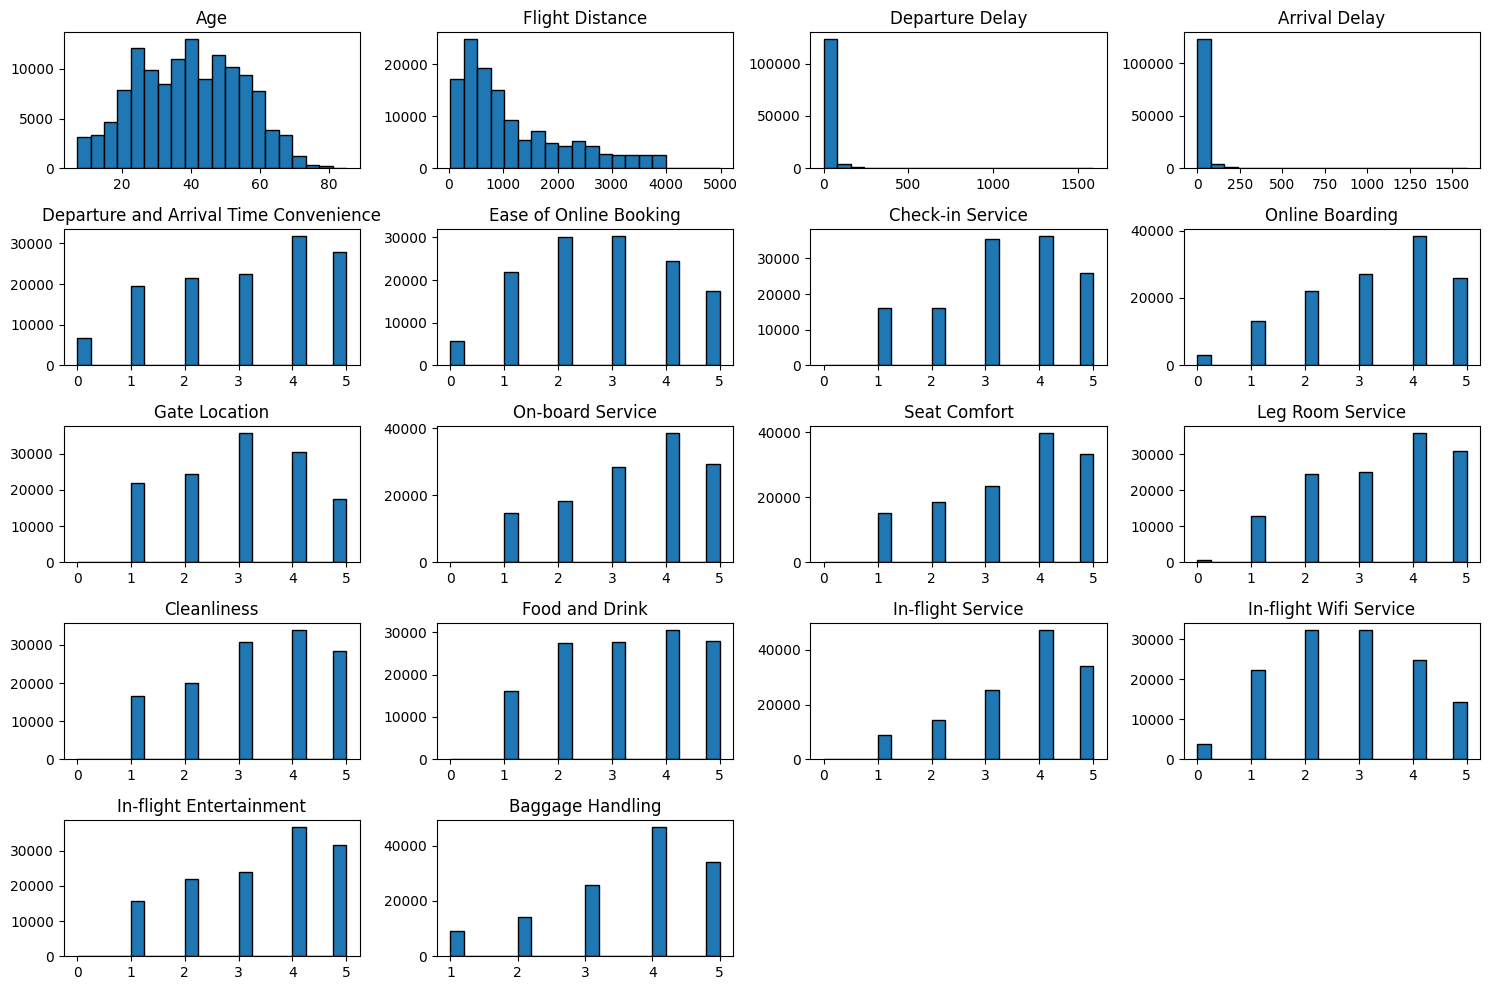

In [15]:
#Histograms for numeric features
numericDf.hist(figsize=(15,10),bins=20, edgecolor='black', grid=False)
plt.grid(False)
plt.tight_layout()

In [16]:
#Create a dataframe with categorical features
categoricalDf = df.select_dtypes(exclude=[np.number])
categoricalDf

,Gender,Customer Type,Type of Travel,Class,Satisfaction
0,Male,First-time,Business,Business,Neutral or Dissatisfied
1,Female,Returning,Business,Business,Satisfied
2,Male,Returning,Business,Business,Satisfied
3,Male,Returning,Business,Business,Satisfied
4,Female,Returning,Business,Business,Satisfied
...,...,...,...,...,...
129875,Male,Returning,Personal,Economy Plus,Neutral or Dissatisfied
129876,Male,Returning,Personal,Economy Plus,Neutral or Dissatisfied
129877,Male,Returning,Personal,Economy Plus,Neutral or Dissatisfied
129878,Male,Returning,Personal,Economy Plus,Satisfied


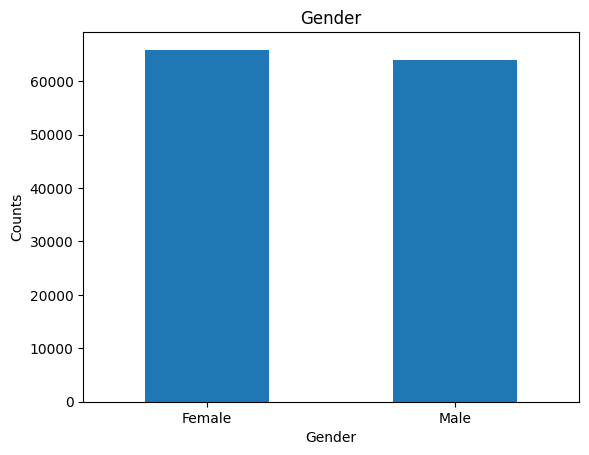

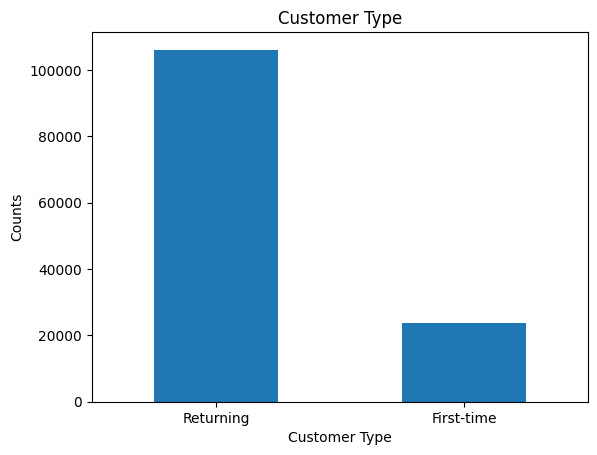

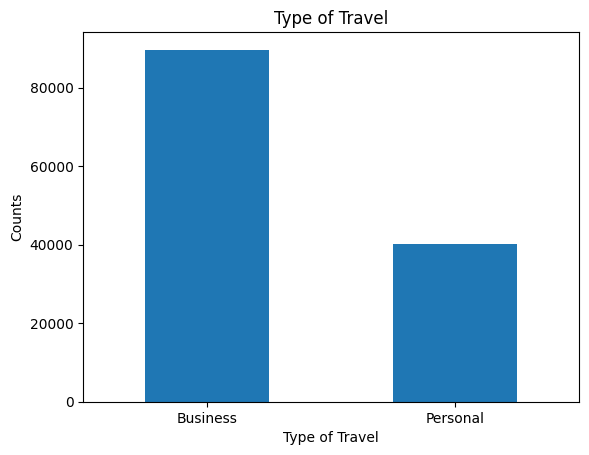

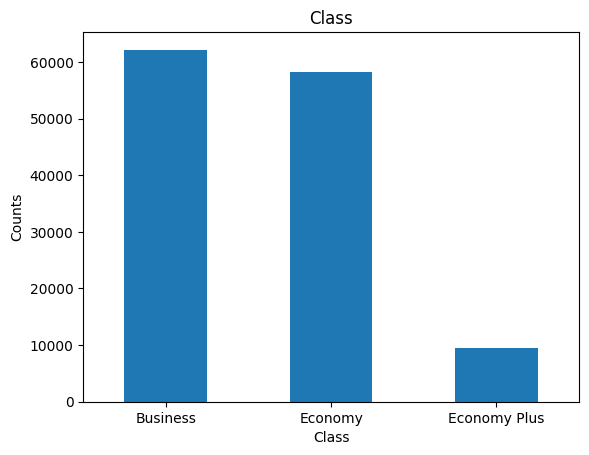

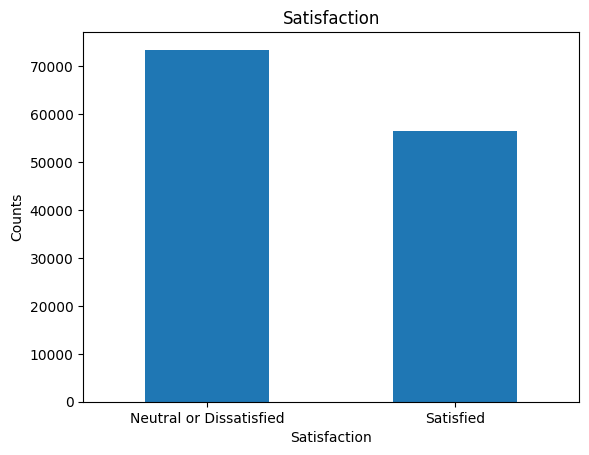

In [17]:
#Bar plot for each of the categorical features
for col in categoricalDf.columns:
  df[col].value_counts().plot.bar(rot=0)
  plt.title(col)
  plt.xlabel(col)
  plt.ylabel('Counts')
  plt.show()

Παρατηρούμε ότι υπάρχει ανισορροπία κλάσης στα features "Customer Type", "Type of Travel" και "Class". Πιο συγκεκριμένα, η κλάση "Returning" είναι περίπου 5 φορές μεγαλύτερη από την κλάση "First-time" ενώ η κλάση "Business" είναι διπλάσια από την κλάση "Personal". Στο Class, οι κλάσεις "Business" και "Economy" είναι πάνω από 5 φορές ισχυρότερες σε σχέση με την "Economy Plus". Τέλος, στο πεδίο Satisfaction που μας ενδιαφέρει ως πεδίο-στόχος, υπάρχει μια ελαφριά ανισορροπία καθώς οι επιβάτες που είναι ουδέτεροι ή δυσαρεστημένοι είναι περισσότεροι από όσους έμειναν ικανοποιημένοι.

### ΕΡΩΤΗΜΑ 2

In [18]:
#Binary encoding for Gender, Customer Type, Type of Travel
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})
df['Customer Type'] = df['Customer Type'].map({'Returning': 0, 'First-time': 1})
df['Type of Travel'] = df['Type of Travel'].map({'Business': 0, 'Personal': 1})

#One-hot vector encoding for Class
df = pd.get_dummies(df, columns=['Class'], dtype=int)
print(df.columns.tolist())


['ID', 'Gender', 'Age', 'Customer Type', 'Type of Travel', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling', 'Satisfaction', 'Class_Business', 'Class_Economy', 'Class_Economy Plus']


### ΕΡΩΤΗΜΑ 3

In [19]:
#Convert df to features array, excluding ID and the target column
x = df.drop(columns=['ID', 'Satisfaction']).to_numpy()
x
print(np.isnan(x).any())
print(np.isnan(x).sum())
print(x.shape)

True
393
(129880, 24)


Παρατηρούμε ότι υπάρχουν σειρές με κενές τιμές (NaN), που δημιουργεί πρόβλημα στον kNN ο οποίος δεν μπορεί να λειτουργήσει με κενές τιμές. Ο αριθμός αυτών των εγγραφών είναι αμελητέος σε σχέση με το μέγεθος του πίνακα, οπότε θα προχωρήσουμε στην αφαίρεση αυτών των εγγραφών.

In [20]:
#Convert target column to y array
y = df['Satisfaction'].to_numpy()
y

array(['Neutral or Dissatisfied', 'Satisfied', 'Satisfied', ...,
       'Neutral or Dissatisfied', 'Satisfied', 'Neutral or Dissatisfied'],
      dtype=object)

In [21]:
#Remove the rows that contain Nan values, both from x and y
mask = np.isnan(x).any(axis=1)
x = x[~mask]
y = y[~mask]
print(x.shape)
print(y.shape)

(129487, 24)
(129487,)


In [22]:
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.7, test_size=0.3, random_state=0)

### ΕΡΩΤΗΜΑ 4

In [23]:
#Data Normalization with StandardScaler
scaler = StandardScaler()
scaler.fit(x_train)

scaled_x_train = scaler.transform(x_train)
scaled_x_test = scaler.transform(x_test)

Χρησιμοποιούμε Standard Scaler (z-score) για την κανονικοποίηση των δεδομένων, καθώς πρόκειται να χρησιμοποιήσουμε τον kNN και ενδιαφερόμαστε για τον σωστό και συνεπή υπολογισμό των αποστάσεων αλλά και γιατί το z-score χειρίζεται πιο ανθεκτικά τις ακραίες τιμές.

### ΕΡΩΤΗΜΑ 5

In [24]:
k_values = [3,5,15,51,151,round(math.sqrt(len(x_train)))]
weights = ['uniform', 'distance']

results = []

for k in k_values:
  for w in weights:
    knn_model = KNeighborsClassifier(n_neighbors=k, weights=w, metric='euclidean')
    knn_model.fit(scaled_x_train, y_train)

    #Running the model predictions against training and test sets
    y_prediction_train = knn_model.predict(scaled_x_train)
    y_prediction_test = knn_model.predict(scaled_x_test)

    #Calculation of accuracy scores
    train_accuracy = accuracy_score(y_train, y_prediction_train)
    test_accuracy = accuracy_score(y_test, y_prediction_test)

    results.append({'k': k, 'weights': w, 'train_accuracy': train_accuracy, 'test_accuracy': test_accuracy})

results_df = pd.DataFrame(results)
results_df

,k,weights,train_accuracy,test_accuracy
0,3,uniform,0.957568,0.925580
1,3,distance,1.000000,0.925477
2,5,uniform,0.947827,0.926326
3,5,distance,1.000000,0.926223
4,15,uniform,0.933263,0.926996
5,15,distance,1.000000,0.927459
6,51,uniform,0.920962,0.920123
7,51,distance,1.000000,0.921796
8,151,uniform,0.909488,0.907432
9,151,distance,1.000000,0.909723


Παρατηρούμε ότι ο καλύτερος συνδυασμός είναι **(k = 15, 'distance')** που σημαίνει ότι όλοι οι γείτονες δεν έχουν την ίδια βαρύτητα, και βασιζόμαστε στην αυξημένη επιρροή των κοντινότερων γειτόνων. Παρατηρούμε πολύ κοντινή απόδοση ανάμεσα στις μεθόδους uniform και distance για τους συντελεστές, με το distance να επιτυγχάνει οριακά υψηλότερη ακρίβεια. Σχετικά με το πλήθος k, παρατηρούμε ότι η υψηλότερη ακρίβεια έρχεται για k = 15 που είναι σχετικά μεγάλος αριθμός. Παρατηρούμε ότι η υψηλότερη ακρίβεια έρχεται όταν εξετάζουμε ελαφρώς πιο απομακρυσμένες παρατηρήσεις.